# Predicting 10-Year Coronary Heart Disease Risk

**Goal:** estimate each patient's probability of developing coronary heart disease (CHD) within ten years, using routine baseline measurements: age, blood pressure, cholesterol, glucose, smoking and medical history.

**Why it matters:** a screening tool like this helps clinicians decide who to follow up first. Missing a patient who goes on to develop CHD (a false negative) is far more costly than an extra check-up for a healthy one (a false positive), so the model is judged mainly on how well it finds true cases, not on raw accuracy.

**Data:** 4,240 participants from the Framingham Heart Study, as released publicly on Kaggle. The target is `TenYearCHD` (1 = developed CHD within ten years).

**Outline**
1. Load and inspect the data
2. Data quality
3. Exploratory analysis
4. Train/test split
5. Preprocessing pipeline
6. Models: baseline, logistic regression, random forest
7. Test-set evaluation
8. Choosing a decision threshold
9. What drives the predictions
10. Scoring a new patient
11. Conclusions and limitations

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.preprocessing import SmokerAwareCigsImputer

DATA_PATH = ROOT / "data" / "framingham.csv"
FIG_DIR = ROOT / "reports" / "figures"
MODEL_DIR = ROOT / "models"
FIG_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TARGET = "TenYearCHD"
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

## 1. Load and inspect the data

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

4,240 rows x 16 columns


,sex,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


| Column | Meaning |
|---|---|
| `sex` | 1 = male, 0 = female |
| `age` | Age in years at the baseline exam |
| `education` | Education level, 1 (lowest) to 4 (highest) |
| `currentSmoker` | 1 = smokes at baseline |
| `cigsPerDay` | Cigarettes smoked per day |
| `BPMeds` | 1 = on blood-pressure medication |
| `prevalentStroke` | 1 = previous stroke |
| `prevalentHyp` | 1 = hypertensive |
| `diabetes` | 1 = diabetic |
| `totChol` | Total cholesterol (mg/dL) |
| `sysBP`, `diaBP` | Systolic / diastolic blood pressure (mmHg) |
| `BMI` | Body-mass index (kg/m²) |
| `heartRate` | Resting heart rate (beats/min) |
| `glucose` | Blood glucose (mg/dL) |
| `TenYearCHD` | **Target:** CHD within ten years |

In [3]:
df.dtypes.to_frame('dtype').T

,sex,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
dtype,int64,int64,float64,int64,float64,float64,int64,int64,int64,float64,float64,float64,float64,float64,float64,int64


## 2. Data quality

In [4]:
missing = (
    df.isna().sum().to_frame("missing")
    .assign(percent=lambda t: 100 * t["missing"] / len(df))
    .query("missing > 0")
    .sort_values("missing", ascending=False)
)
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Rows with at least one missing value: {df.isna().any(axis=1).sum()} ({df.isna().any(axis=1).mean():.1%})")
missing

Duplicate rows: 0
Rows with at least one missing value: 582 (13.7%)


,missing,percent
glucose,388,9.151
education,105,2.476
BPMeds,53,1.250
totChol,50,1.179
cigsPerDay,29,0.684
BMI,19,0.448
heartRate,1,0.024


Dropping every incomplete row would lose about 14% of the data, so missing values are filled in instead, inside the model pipeline (section 5).

`cigsPerDay` needs care. If its missing values are filled with the overall median, the result is **0**, because about half the cohort does not smoke. The check below shows who the missing values belong to:

In [5]:
print("Smoking status of rows with missing cigsPerDay:")
print(df.loc[df["cigsPerDay"].isna(), "currentSmoker"].value_counts().rename({1: "smoker", 0: "non-smoker"}))
print(f"\nOverall median cigsPerDay: {df['cigsPerDay'].median():.0f}")
print(f"Median among smokers:      {df.loc[df['currentSmoker'] == 1, 'cigsPerDay'].median():.0f}")

Smoking status of rows with missing cigsPerDay:
currentSmoker
smoker    29
Name: count, dtype: int64

Overall median cigsPerDay: 0
Median among smokers:      20


Every missing `cigsPerDay` belongs to a **smoker**, so filling with the overall median would record smokers as smoking nothing. The pipeline uses a smoker-aware rule instead (`src/preprocessing.py`): non-smokers get 0, and smokers get the median for smokers in the training data.

Next, a plausibility check on the measurement ranges:

In [6]:
df.describe().T[['mean', 'min', '50%', 'max']]

,mean,min,50%,max
sex,0.429,0.00,0.0,1.0
age,49.580,32.00,49.0,70.0
education,1.979,1.00,2.0,4.0
currentSmoker,0.494,0.00,0.0,1.0
cigsPerDay,9.006,0.00,0.0,70.0
BPMeds,0.030,0.00,0.0,1.0
prevalentStroke,0.006,0.00,0.0,1.0
prevalentHyp,0.311,0.00,0.0,1.0
diabetes,0.026,0.00,0.0,1.0
totChol,236.700,107.00,234.0,696.0


The extremes are high but physiologically possible: a systolic BP of 295, glucose of 394 (untreated diabetes) and cholesterol of 696 (familial hypercholesterolaemia). They are kept, because removing real high-risk patients would bias a risk model. Tree models are unaffected by outliers, and the logistic regression works on standardised features.

## 3. Exploratory analysis

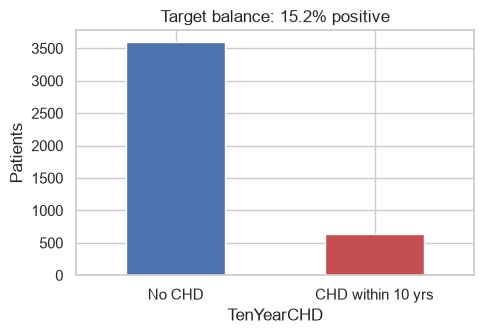

In [7]:
rate = df[TARGET].mean()
ax = df[TARGET].value_counts().sort_index().plot.bar(color=["#4C72B0", "#C44E52"], figsize=(5, 3.5))
ax.set_xticklabels(["No CHD", "CHD within 10 yrs"], rotation=0)
ax.set_ylabel("Patients")
ax.set_title(f"Target balance: {rate:.1%} positive")
plt.tight_layout()
plt.savefig(FIG_DIR / "target_balance.png", dpi=120)
plt.show()

Only about **15%** of patients develop CHD. A model that always predicts "no CHD" would be about 85% accurate and completely useless, so accuracy is not used to judge the models. They are compared on **ROC-AUC**, **PR-AUC** (average precision, which focuses on the rare positive class) and **recall**.

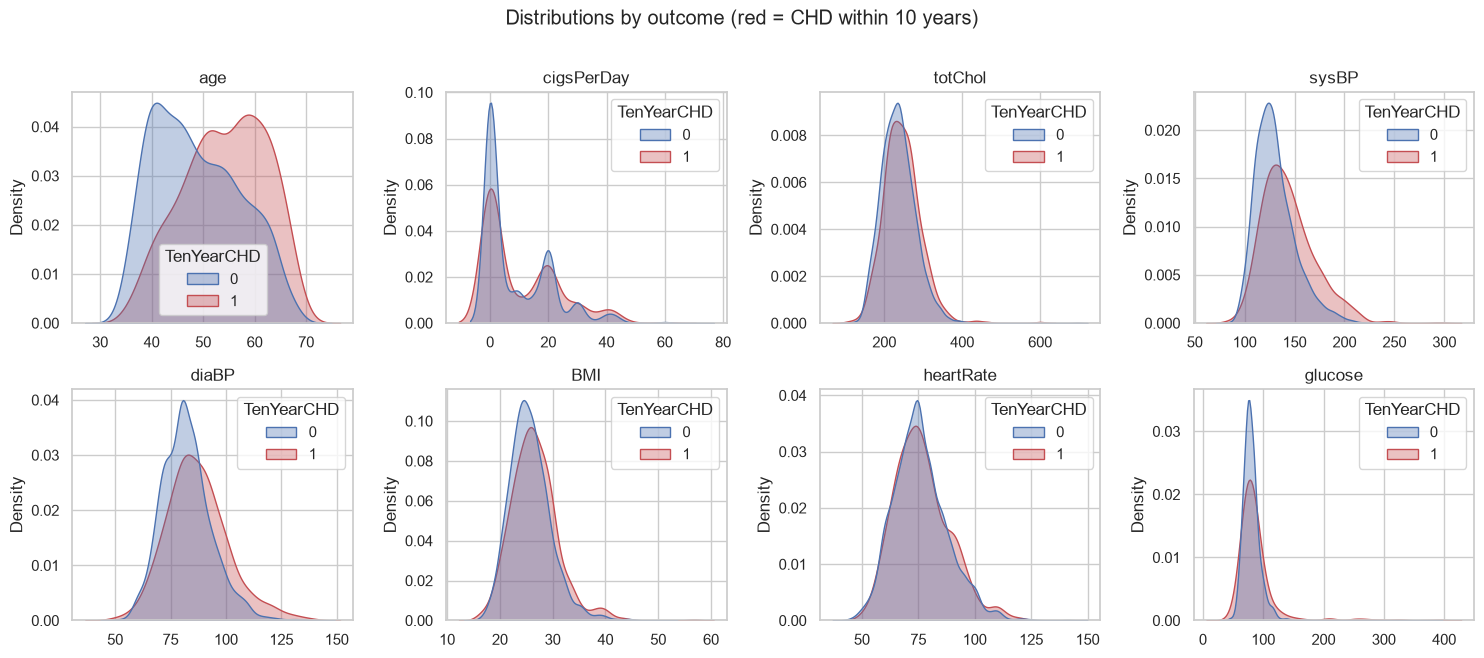

In [8]:
numeric = ["age", "cigsPerDay", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]
binary = ["sex", "education", "currentSmoker", "BPMeds", "prevalentStroke", "prevalentHyp", "diabetes"]

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, col in zip(axes.flat, numeric):
    sns.kdeplot(data=df, x=col, hue=TARGET, common_norm=False, fill=True, alpha=0.35, ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Distributions by outcome (red = CHD within 10 years)", y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "distributions_by_outcome.png", dpi=120, bbox_inches="tight")
plt.show()

In [9]:
flags = [c for c in binary if c != "education"]
rates = pd.DataFrame({
    "CHD rate if 0": [df.loc[df[c] == 0, TARGET].mean() for c in flags],
    "CHD rate if 1": [df.loc[df[c] == 1, TARGET].mean() for c in flags],
    "patients with 1": [int((df[c] == 1).sum()) for c in flags],
}, index=flags)
rates["ratio"] = rates["CHD rate if 1"] / rates["CHD rate if 0"]
rates.sort_values("ratio", ascending=False).round(3)

,CHD rate if 0,CHD rate if 1,patients with 1,ratio
prevalentStroke,0.150,0.440,25,2.930
diabetes,0.146,0.367,109,2.510
BPMeds,0.146,0.331,124,2.269
prevalentHyp,0.109,0.247,1317,2.261
sex,0.124,0.188,1820,1.515
currentSmoker,0.145,0.159,2095,1.096


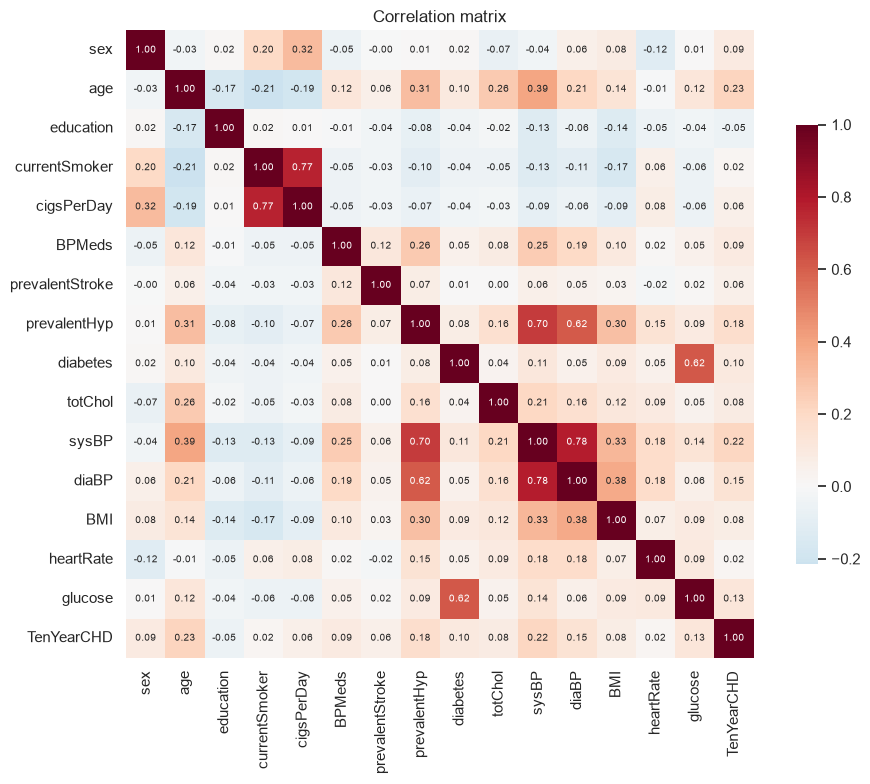

Strongest correlations with the target:
age             0.225
sysBP           0.216
prevalentHyp    0.177
diaBP           0.145
glucose         0.126
diabetes        0.097
Name: TenYearCHD, dtype: float64


In [10]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, square=True, cbar_kws={"shrink": 0.7})
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig(FIG_DIR / "correlation_matrix.png", dpi=120)
plt.show()

print("Strongest correlations with the target:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).head(6).round(3))

**Takeaways**
- **Age** separates the classes most clearly: patients who developed CHD are noticeably older.
- **Blood pressure** (`sysBP`, `diaBP`, `prevalentHyp`) is the next strongest signal. These three are strongly correlated with each other, which matters when interpreting the linear model's coefficients.
- **Glucose** and **diabetes** carry signal mainly through a long right tail of very high values.
- `currentSmoker` and `cigsPerDay` are strongly correlated, and `cigsPerDay` carries the extra information about how much a person smokes.
- `heartRate` and `education` show little difference between the classes.

## 4. Train/test split

The test set is set aside **before** any filling-in or fitting, so nothing learned from it leaks into the model. The split is stratified to keep the 15% positive rate in both parts.

In [11]:
X = df.drop(columns=TARGET)
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape[0]:,} rows ({y_train.mean():.1%} positive)")
print(f"Test:  {X_test.shape[0]:,} rows ({y_test.mean():.1%} positive)")

Train: 3,392 rows (15.2% positive)
Test:  848 rows (15.2% positive)


## 5. Preprocessing pipeline

All preprocessing lives inside a scikit-learn `Pipeline`, so it is learned from the training folds only during cross-validation and is applied the same way to new patients.

1. `SmokerAwareCigsImputer`: the fix for `cigsPerDay` from section 2.
2. Numeric features: fill with the median, add a missing-value indicator (glucose is 9% missing, and whether it was missing may itself be informative), then standardise.
3. Binary and ordinal features: fill with the most frequent value.

In [12]:
def make_preprocessor():
    num_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    cat_pipe = SimpleImputer(strategy="most_frequent")
    columns = ColumnTransformer(
        [("num", num_pipe, numeric), ("cat", cat_pipe, binary)],
        verbose_feature_names_out=False,
    )
    return Pipeline([("cigs", SmokerAwareCigsImputer()), ("columns", columns)])


def make_model(estimator):
    return Pipeline([("prep", make_preprocessor()), ("clf", estimator)])

## 6. Models

Three candidates, each scored with 5-fold stratified cross-validation on the **training set only**:

- **Baseline:** always predicts the majority class. Any real model must beat it.
- **Logistic regression:** interpretable and a strong baseline for tabular medical data. `class_weight="balanced"` makes the rare CHD cases count more.
- **Random forest:** captures non-linear effects and interactions. Its tree depth and leaf size are tuned, because unconstrained forests overfit badly on 3,400 rows.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall"}

lr_search = GridSearchCV(
    make_model(LogisticRegression(class_weight="balanced", max_iter=2000)),
    {"clf__C": [0.01, 0.1, 1, 10]},
    scoring="average_precision", cv=cv, n_jobs=-1,
).fit(X_train, y_train)

rf_search = GridSearchCV(
    make_model(RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1)),
    {"clf__max_depth": [4, 6, 8], "clf__min_samples_leaf": [5, 20, 50]},
    scoring="average_precision", cv=cv, n_jobs=-1,
).fit(X_train, y_train)

print("Best logistic regression:", lr_search.best_params_)
print("Best random forest:      ", rf_search.best_params_)

models = {
    "Baseline (majority class)": make_model(DummyClassifier(strategy="most_frequent")),
    "Logistic regression": lr_search.best_estimator_,
    "Random forest": rf_search.best_estimator_,
}
cv_rows, cv_pr_auc = {}, {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    cv_rows[name] = {m: f"{scores['test_' + m].mean():.3f} ± {scores['test_' + m].std():.3f}" for m in scoring}
    cv_pr_auc[name] = scores["test_pr_auc"].mean()
pd.DataFrame(cv_rows).T.rename(columns={"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC", "recall": "Recall (0.5 threshold)"})

Best logistic regression: {'clf__C': 0.01}
Best random forest:       {'clf__max_depth': 8, 'clf__min_samples_leaf': 20}


,ROC-AUC,PR-AUC,Recall (0.5 threshold)
Baseline (majority class),0.500 ± 0.000,0.152 ± 0.000,0.000 ± 0.000
Logistic regression,0.737 ± 0.028,0.362 ± 0.034,0.687 ± 0.040
Random forest,0.720 ± 0.032,0.347 ± 0.045,0.548 ± 0.054


In [14]:
best_name = max((n for n in cv_pr_auc if not n.startswith("Baseline")), key=cv_pr_auc.get)
print(f"Selected on cross-validated PR-AUC: {best_name}")

Selected on cross-validated PR-AUC: Logistic regression


The final model is chosen here, on cross-validated PR-AUC, **before** the test set is touched. The two models are within one standard deviation of each other, so the simpler and more interpretable logistic regression is a sensible choice even if the random forest edges ahead on one split. The tuned scores are slightly optimistic because the hyperparameters were picked on the same folds. The untouched test set in section 7 gives the honest estimate.

## 7. Test-set evaluation

The test set is used **once**, here, after every modelling choice has been made.

In [15]:
fitted = {name: m.fit(X_train, y_train) for name, m in models.items()}
probs = {name: m.predict_proba(X_test)[:, 1] for name, m in fitted.items()}

test_table = pd.DataFrame({
    name: {
        "ROC-AUC": roc_auc_score(y_test, p),
        "PR-AUC": average_precision_score(y_test, p),
    }
    for name, p in probs.items()
}).T
test_table["PR-AUC lift over random"] = test_table["PR-AUC"] / y_test.mean()
test_table.round(3)

,ROC-AUC,PR-AUC,PR-AUC lift over random
Baseline (majority class),0.500,0.152,1.000
Logistic regression,0.691,0.278,1.824
Random forest,0.678,0.286,1.882


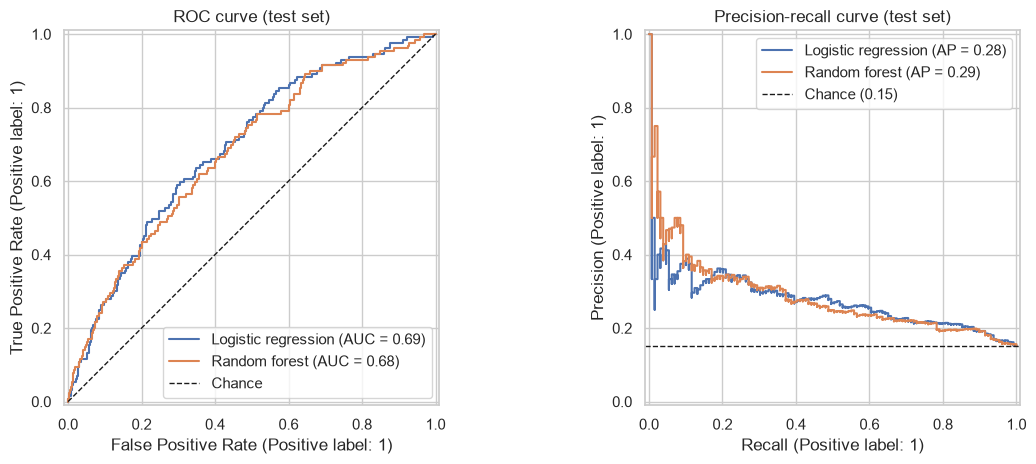

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for name in ["Logistic regression", "Random forest"]:
    RocCurveDisplay.from_predictions(y_test, probs[name], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, probs[name], name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
axes[0].legend(loc="lower right")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Chance ({y_test.mean():.2f})")
axes[1].legend(loc="upper right")
axes[0].set_title("ROC curve (test set)")
axes[1].set_title("Precision-recall curve (test set)")
plt.tight_layout()
plt.savefig(FIG_DIR / "roc_pr_curves.png", dpi=120)
plt.show()

**Calibration.** For a risk tool, a predicted "30% risk" should mean about 30% of such patients develop CHD. `class_weight="balanced"` deliberately pushes probabilities upward, so the curves below show how far the raw scores sit from the true rates. The scores are still useful for **ranking** patients, but they would need recalibrating (for example with `CalibratedClassifierCV`) before being shown to clinicians as absolute risks.

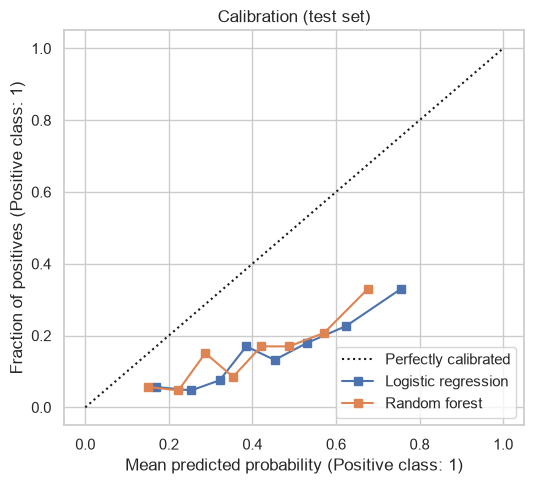

In [17]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for name in ["Logistic regression", "Random forest"]:
    CalibrationDisplay.from_predictions(y_test, probs[name], n_bins=8, strategy="quantile", name=name, ax=ax)
ax.set_title("Calibration (test set)")
plt.tight_layout()
plt.savefig(FIG_DIR / "calibration.png", dpi=120)
plt.show()

## 8. Choosing a decision threshold

The default 0.5 cut-off is arbitrary. The working assumption here is that the screening goal is to **catch at least 70% of future CHD cases**. The threshold is chosen from **out-of-fold predictions on the training set** (never from the test set), then applied unchanged to the test set.

Model carried forward (chosen in section 6): Logistic regression


Threshold giving ≥70% recall on training folds: 0.490


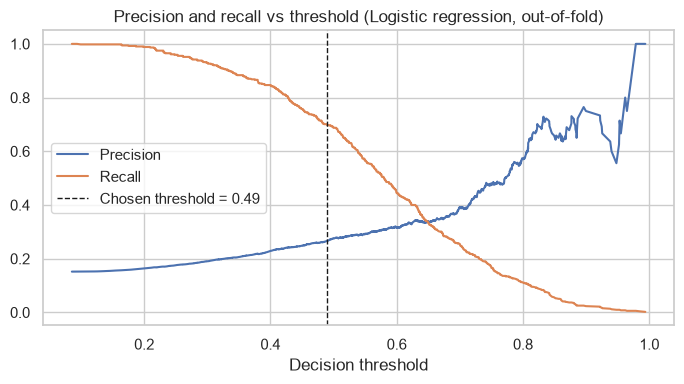

In [18]:
TARGET_RECALL = 0.70
best_model = fitted[best_name]
print(f"Model carried forward (chosen in section 6): {best_name}")

oof = cross_val_predict(models[best_name], X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
threshold = float(thr[rec[:-1] >= TARGET_RECALL].max())
print(f"Threshold giving ≥{TARGET_RECALL:.0%} recall on training folds: {threshold:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thr, prec[:-1], label="Precision")
ax.plot(thr, rec[:-1], label="Recall")
ax.axvline(threshold, color="k", ls="--", lw=1, label=f"Chosen threshold = {threshold:.2f}")
ax.set_xlabel("Decision threshold")
ax.set_title(f"Precision and recall vs threshold ({best_name}, out-of-fold)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "threshold.png", dpi=120)
plt.show()

              precision    recall  f1-score   support

      No CHD      0.903     0.663     0.765       719
         CHD      0.244     0.605     0.347       129

    accuracy                          0.654       848
   macro avg      0.574     0.634     0.556       848
weighted avg      0.803     0.654     0.702       848

Of 129 test patients who developed CHD, the model flags 78 and misses 51.
To find them it flags 320 of 848 patients (38%) for follow-up.


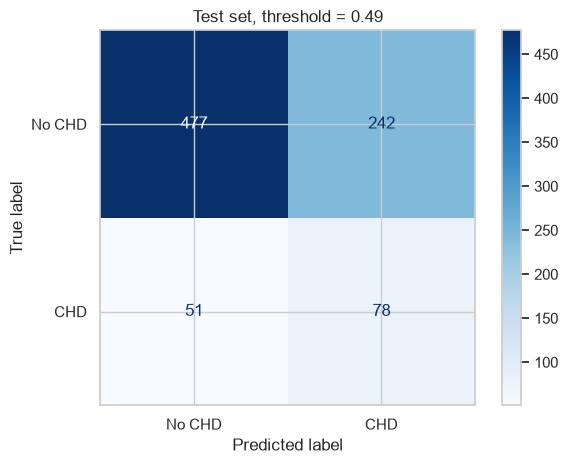

In [19]:
y_pred = (probs[best_name] >= threshold).astype(int)
print(classification_report(y_test, y_pred, target_names=["No CHD", "CHD"], digits=3))

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"Of {tp + fn} test patients who developed CHD, the model flags {tp} and misses {fn}.")
print(f"To find them it flags {tp + fp} of {len(y_test)} patients ({(tp + fp) / len(y_test):.0%}) for follow-up.")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No CHD", "CHD"], cmap="Blues")
plt.title(f"Test set, threshold = {threshold:.2f}")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix.png", dpi=120)
plt.show()

## 9. What drives the predictions

**Logistic regression odds ratios.** The numeric features are standardised, so each odds ratio is the change in odds for a **one standard deviation** increase (for binary features, for having the condition).

In [20]:
lr = fitted["Logistic regression"]
names = lr.named_steps["prep"].named_steps["columns"].get_feature_names_out()
odds = (
    pd.Series(np.exp(lr.named_steps["clf"].coef_[0]), index=names, name="odds ratio")
    .sort_values(ascending=False)
)
odds.round(2).to_frame()

,odds ratio
age,1.70
sex,1.31
sysBP,1.27
cigsPerDay,1.25
missingindicator_BMI,1.16
glucose,1.15
prevalentHyp,1.14
BPMeds,1.12
totChol,1.11
missingindicator_totChol,1.10


**Permutation importance** (model-agnostic, computed on the test set): how much PR-AUC drops when each feature is shuffled.

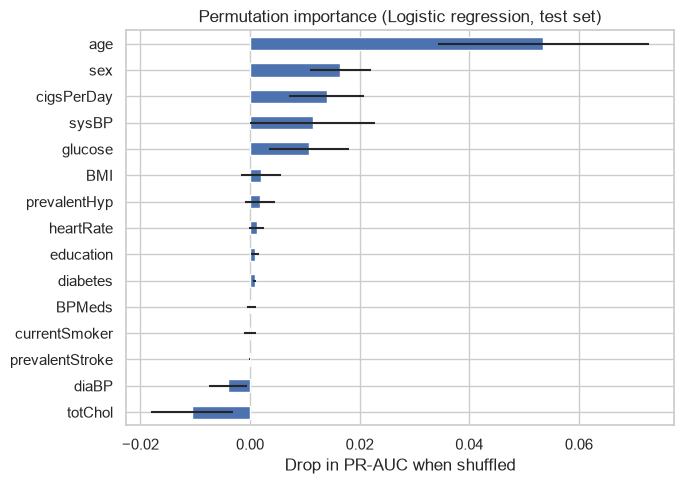

In [21]:
perm = permutation_importance(
    best_model, X_test, y_test, scoring="average_precision", n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1
)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
ax = imp.plot.barh(figsize=(7, 5), color="#4C72B0", xerr=pd.Series(perm.importances_std, index=X_test.columns)[imp.index])
ax.set_xlabel("Drop in PR-AUC when shuffled")
ax.set_title(f"Permutation importance ({best_name}, test set)")
plt.tight_layout()
plt.savefig(FIG_DIR / "permutation_importance.png", dpi=120)
plt.show()

Both views agree with established cardiology: **age**, **sex** (male), **smoking intensity**, **systolic blood pressure** and **glucose** lead. A model whose top drivers matched no known risk factors would be a warning sign of leakage or a data problem.

Two caveats:
- The chosen regularisation is strong (`C=0.01`), which shrinks every odds ratio towards 1, so read the **ranking** rather than the exact sizes.
- Features with zero or slightly negative permutation importance (`diaBP`, `totChol`) add nothing beyond the others on this test set. That is expected for `diaBP`, which largely duplicates `sysBP`.

## 10. Scoring a new patient

The final model is retrained on **all** the data and saved, together with the chosen threshold. Here is how it would score a new patient:

In [22]:
final_model = models[best_name].fit(X, y)
MODEL_DIR.mkdir(exist_ok=True)
joblib.dump({"model": final_model, "threshold": threshold}, MODEL_DIR / "chd_model.joblib")

new_patient = pd.DataFrame([{
    "sex": 1, "age": 58, "education": 2, "currentSmoker": 1, "cigsPerDay": np.nan,
    "BPMeds": 0, "prevalentStroke": 0, "prevalentHyp": 1, "diabetes": 0,
    "totChol": 260, "sysBP": 152, "diaBP": 94, "BMI": 29.1, "heartRate": 78, "glucose": np.nan,
}])
score = final_model.predict_proba(new_patient)[0, 1]
print(f"Risk score: {score:.2f} -> {'FLAG for follow-up' if score >= threshold else 'routine care'}")

Risk score: 0.73 -> FLAG for follow-up


The patient's `cigsPerDay` and `glucose` are missing on purpose. The pipeline fills them in the same way it did in training.

## 11. Conclusions and limitations

**Results**
- **Logistic regression** was selected on cross-validated PR-AUC (0.36 against 0.35 for the random forest). The random forest's extra complexity bought nothing on this data.
- On the untouched test set it reaches **ROC-AUC 0.69** and **PR-AUC 0.28**, about **1.8×** the 0.15 achieved by guessing. The test scores sit below the cross-validation estimates (0.74 / 0.36): the test set is only 129 positive cases, so some variation from split to split is expected, and the tuned CV scores are slightly optimistic.
- At the threshold chosen on training data (0.49), the model **catches 78 of 129 future CHD cases (60% recall)** while flagging 38% of patients for follow-up. That falls short of the 70% target set on the training folds, which is an honest reminder that a threshold tuned on one sample moves on another.
- The main drivers are **age, sex, smoking intensity, systolic blood pressure and glucose**. These match the established Framingham risk factors, which is good evidence that the pipeline is sound.
- Fixing `cigsPerDay` mattered for interpretation: smoking intensity is one of the top five predictors, and the old fill would have recorded 29 smokers as non-smokers.

**How good is this?** A ROC-AUC near 0.7 is typical for this dataset, and the published Framingham risk equations reach about 0.7–0.8 using more detailed variables. The model is a reasonable screening aid for ranking patients, not a diagnostic test.

**Limitations**
- **Population:** the Framingham cohort is from a single US town, mostly white, and was recruited decades ago. Performance on other populations is unknown and needs external validation.
- **Calibration:** the class-weighted models overestimate absolute risk (section 7). They are fine for ranking patients, but would need recalibrating before showing clinicians a percentage.
- **Size:** about 640 positive cases limit how complex a model the data can support.
- **Observational data:** the odds ratios describe associations, not the effect of treating a risk factor.
- **Threshold:** the 70% recall target is an assumption. In practice it would be set together with clinicians, based on follow-up capacity.

**Next steps:** recalibrate the probabilities, compare against the published Framingham risk score, try gradient boosting, and validate on an external cohort.